# AI-Based Micro-Zone Disaster Risk Scoring System

In [ ]:
import os
import json
import math
from datetime import datetime, timezone

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import roc_auc_score, classification_report
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LogisticRegression

import joblib

import plotly.express as px
import plotly.io as pio

# Geo stack
import geopandas as gpd
from shapely.geometry import Polygon, Point

# ML extras
from xgboost import XGBRegressor
import shap

import seaborn as sns
import matplotlib.pyplot as plt

import folium

# Plotly inline rendering can break in some notebook environments due to renderer/nbformat detection.
# Use a safe default so `fig.show()` doesn't stop notebook execution.
pio.renderers.default = "browser"

WORKSPACE_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..'))
DATA_DIR = os.path.join(WORKSPACE_ROOT, 'data')
MODELS_DIR = os.path.join(WORKSPACE_ROOT, 'models')
API_DIR = os.path.join(WORKSPACE_ROOT, 'api')

os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(API_DIR, exist_ok=True)

np.random.seed(42)
pd.set_option('display.max_columns', 200)
print('Workspace root:', WORKSPACE_ROOT)
print('Data dir:', DATA_DIR)
print('Models dir:', MODELS_DIR)
print('API dir:', API_DIR)

Workspace root: d:\AI-Based Micro-Zone Disaster Risk Scoring System
Data dir: d:\AI-Based Micro-Zone Disaster Risk Scoring System\data
Models dir: d:\AI-Based Micro-Zone Disaster Risk Scoring System\models
API dir: d:\AI-Based Micro-Zone Disaster Risk Scoring System\api


# DATA COLLECTION LAYER

In [4]:
def pick_utm_crs_for_lonlat(lon: float, lat: float) -> str:
    """Return a UTM CRS string for a given lon/lat."""
    zone_number = int((lon + 180) / 6) + 1
    is_northern = lat >= 0
    epsg = 32600 + zone_number if is_northern else 32700 + zone_number
    return f"EPSG:{epsg}"

def create_city_grid(
    city_center_lonlat=(77.2090, 28.6139),  # default: Delhi-ish
    half_size_km=10.0,
    grid_size_km=2.0,
) -> gpd.GeoDataFrame:
    """Create a GeoDataFrame grid of micro-zones (polygons) in meters using a UTM projection."""
    lon0, lat0 = city_center_lonlat
    crs_wgs84 = "EPSG:4326"
    utm_crs = pick_utm_crs_for_lonlat(lon0, lat0)

    # Start from a point then buffer to get a square bbox in meters
    gdf_center = gpd.GeoDataFrame(
        {"name": ["center"]},
        geometry=[Point(lon0, lat0)],
        crs=crs_wgs84,
).to_crs(utm_crs)

    center_pt = gdf_center.geometry.iloc[0]
    half_size_m = half_size_km * 1000.0
    grid_m = grid_size_km * 1000.0

    minx, miny = center_pt.x - half_size_m, center_pt.y - half_size_m
    maxx, maxy = center_pt.x + half_size_m, center_pt.y + half_size_m

    xs = np.arange(minx, maxx, grid_m)
    ys = np.arange(miny, maxy, grid_m)

    polygons = []
    zone_ids = []
    idx = 1
    for x in xs:
        for y in ys:
            poly = Polygon([(x, y), (x + grid_m, y), (x + grid_m, y + grid_m), (x, y + grid_m)])
            polygons.append(poly)
            zone_ids.append(f"Z{idx:04d}")
            idx += 1

    grid = gpd.GeoDataFrame(
        {"Zone_ID": zone_ids},
        geometry=polygons,
        crs=utm_crs,
)

    # Convert to WGS84 for mapping (Folium expects lat/lon)
    grid_wgs84 = grid.to_crs(crs_wgs84)

    # Centroids computed in UTM (stable), then reprojected to WGS84
    centroid_wgs84 = gpd.GeoSeries(grid.geometry.centroid, crs=utm_crs).to_crs(crs_wgs84)
    grid_wgs84["Latitude"] = centroid_wgs84.y.values
    grid_wgs84["Longitude"] = centroid_wgs84.x.values

    return grid_wgs84

zones_gdf = create_city_grid(half_size_km=10.0, grid_size_km=2.0)
print('Zones:', len(zones_gdf))
zones_gdf.head()

Zones: 100


,Zone_ID,geometry,Latitude,Longitude
0,Z0001,"POLYGON ((77.10498 28.52532, 77.12541 28.52501...",28.534185,77.115377
1,Z0002,"POLYGON ((77.10534 28.54336, 77.12577 28.54305...",28.552226,77.115738
2,Z0003,"POLYGON ((77.1057 28.56141, 77.12614 28.56109,...",28.570267,77.116099
3,Z0004,"POLYGON ((77.10606 28.57945, 77.1265 28.57913,...",28.588307,77.116460
4,Z0005,"POLYGON ((77.10642 28.59749, 77.12686 28.59717...",28.606348,77.116822


## Load real historical disaster dataset

In [6]:
DISASTER_CSV_PATH = os.path.join(DATA_DIR, 'disasterIND.csv')

def _to_float(series: pd.Series) -> pd.Series:
    return pd.to_numeric(series, errors='coerce')

def load_disasterIND(csv_path: str) -> pd.DataFrame:
    df = pd.read_csv(csv_path)
    # Normalize column names (keep original but strip spaces)
    df.columns = [c.strip() for c in df.columns]
    # Canonical columns (best-effort)
    col_lat = 'Latitude'
    col_lon = 'Longitude'
    col_year = 'Start Year'
    col_deaths = 'Total Deaths'
    col_affected = 'Total Affected'
    col_damage_adj = "Total Damage, Adjusted ('000 US$')"
    col_type = 'Disaster Type'

    for c in [col_lat, col_lon, col_year, col_deaths, col_affected, col_damage_adj]:
        if c in df.columns:
            df[c] = _to_float(df[c])

    # Build a usable event date (many rows have missing month/day)
    month = _to_float(df.get('Start Month', pd.Series([np.nan]*len(df))))
    day = _to_float(df.get('Start Day', pd.Series([np.nan]*len(df))))
    year = df[col_year] if col_year in df.columns else pd.Series([np.nan]*len(df))
    # Default month/day to mid-year if missing
    month = month.fillna(6).clip(1, 12).astype(int)
    day = day.fillna(15).clip(1, 28).astype(int)
    year_i = year.fillna(0).astype(int)
    df['EventDate'] = pd.to_datetime(dict(year=year_i, month=month, day=day), errors='coerce')
    df['Year'] = df['EventDate'].dt.year.astype('Int64')

    # Severity proxy (robust to missing data):
    # severity = log1p(deaths) + 0.5*log1p(affected) + 0.3*log1p(damage_adj_kusd)
    deaths = df[col_deaths] if col_deaths in df.columns else pd.Series([0.0]*len(df))
    affected = df[col_affected] if col_affected in df.columns else pd.Series([0.0]*len(df))
    damage = df[col_damage_adj] if col_damage_adj in df.columns else pd.Series([0.0]*len(df))
    df['EventSeverity'] = (
        np.log1p(deaths.fillna(0))
        + 0.5 * np.log1p(affected.fillna(0))
        + 0.3 * np.log1p(damage.fillna(0))
    )

    # Keep key columns
    keep = [c for c in ['DisNo.','Country','Location',col_type,col_lat,col_lon,'Year','EventDate','EventSeverity',col_deaths,col_affected,col_damage_adj] if c in df.columns]
    return df[keep].copy()

def assign_events_to_zones_nearest(events: pd.DataFrame, zones: gpd.GeoDataFrame, max_km: float = 10.0) -> pd.DataFrame:
    """Assign each event to the nearest micro-zone centroid using haversine distance (fallback when spatial index isn't available)."""
    from sklearn.neighbors import NearestNeighbors

    ev = events.dropna(subset=['Latitude','Longitude','Year']).copy()
    if ev.empty:
        return ev.assign(Zone_ID=pd.Series(dtype=str))

    # Build centroid table
    cent = zones[['Zone_ID','Latitude','Longitude']].dropna().copy()
    X_cent = np.radians(cent[['Latitude','Longitude']].values)
    X_ev = np.radians(ev[['Latitude','Longitude']].values)

    nn = NearestNeighbors(n_neighbors=1, metric='haversine')
    nn.fit(X_cent)
    d_rad, idx = nn.kneighbors(X_ev)
    # Convert to km (Earth radius ~6371 km)
    d_km = d_rad[:, 0] * 6371.0
    nearest_zone = cent.iloc[idx[:, 0]]['Zone_ID'].values

    ev['Zone_ID'] = np.where(d_km <= max_km, nearest_zone, None)
    ev['Distance_km'] = d_km
    return ev

disaster_hist_real = None
if os.path.exists(DISASTER_CSV_PATH):
    events = load_disasterIND(DISASTER_CSV_PATH)
    print('Loaded disasterIND.csv shape:', events.shape)
    print('Non-null lat/lon:', events[['Latitude','Longitude']].notna().all(axis=1).sum())
    print('Year range:', (events['Year'].min(), events['Year'].max()))
    print('Top Disaster Types:')
    if 'Disaster Type' in events.columns:
        display(events['Disaster Type'].value_counts().head(10))

    # Focus only on events reasonably near our synthetic city grid (otherwise they'll swamp with unrelated locations)
    # We use bounding box + nearest assignment threshold.
    min_lon, min_lat, max_lon, max_lat = zones_gdf.total_bounds
    pad = 1.0  # degrees (~111km). Widen so we don't accidentally drop relevant nearby events.
    in_bbox = events.dropna(subset=['Latitude','Longitude']).copy()
    in_bbox = in_bbox[
        in_bbox['Latitude'].between(min_lat - pad, max_lat + pad)
        & in_bbox['Longitude'].between(min_lon - pad, max_lon + pad)
    ]
    assigned = assign_events_to_zones_nearest(in_bbox, zones_gdf, max_km=20.0)
    assigned = assigned.dropna(subset=['Zone_ID'])

    if assigned.empty:
        print('No disasterIND events were assignable to the current micro-zone extent (likely because the grid is not over the event locations).')
        disaster_hist_real = pd.DataFrame(columns=['Zone_ID','Year','Disaster_Events','Disaster_Severity'])
    else:
        disaster_hist_real = (
            assigned.groupby(['Zone_ID','Year'])
            .agg(
                Disaster_Events=('DisNo.','count'),
                Disaster_Severity=('EventSeverity','sum'),
            )
            .reset_index()
        )
        print('Real disaster history (zone-year) rows:', len(disaster_hist_real))
        display(disaster_hist_real.head())
else:
    print('No data/disasterIND.csv found → using synthetic disaster simulation in the next cells.')

Loaded disasterIND.csv shape: (783, 11)
Non-null lat/lon: 93
Year range: (np.int64(1900), np.int64(2024))
Top Disaster Types:


Disaster Type
Flood                          325
Storm                          214
Epidemic                        69
Extreme temperature             64
Mass movement (wet)             58
Earthquake                      27
Drought                         16
Wildfire                         4
Glacial lake outburst flood      3
Mass movement (dry)              2
Name: count, dtype: int64

No disasterIND events were assignable to the current micro-zone extent (likely because the grid is not over the event locations).


## Simulate datasets

In [7]:
def simulate_zone_static_features(zones: gpd.GeoDataFrame) -> pd.DataFrame:
    # Create smooth spatial gradients
    lat = zones["Latitude"].values
    lon = zones["Longitude"].values

    # Normalize lat/lon to [0,1] for synthetic spatial patterns
    lat_n = (lat - lat.min()) / (lat.max() - lat.min() + 1e-9)
    lon_n = (lon - lon.min()) / (lon.max() - lon.min() + 1e-9)

    # Elevation: gradient + noise (meters)
    elevation = 80 + 120 * (0.6 * lat_n + 0.4 * lon_n) + np.random.normal(0, 8, size=len(zones))

    # Population density: hotspot near an arbitrary point (people/km^2)
    hotspot_lat, hotspot_lon = lat.mean() + 0.01, lon.mean() - 0.01
    dist2 = (lat - hotspot_lat) ** 2 + (lon - hotspot_lon) ** 2
    pop_density = 1500 + 9000 * np.exp(-dist2 / (2 * (0.02 ** 2))) + np.random.normal(0, 250, size=len(zones))
    pop_density = np.clip(pop_density, 100, None)

    df = pd.DataFrame({
        "Zone_ID": zones["Zone_ID"].values,
        "Elevation_m": elevation,
        "Population_Density": pop_density,
    })
    return df

def simulate_weather_daily(start_date: str, end_date: str) -> pd.DataFrame:
    dates = pd.date_range(start=start_date, end=end_date, freq="D")
    n = len(dates)

    # Seasonal patterns
    day_of_year = dates.dayofyear.values
    # Temperature (C): sinusoid + noise
    temp = 22 + 10 * np.sin(2 * np.pi * (day_of_year / 365.25)) + np.random.normal(0, 1.8, n)
    # Humidity (%): inverse-ish relation to temperature + season
    humidity = 65 - 12 * np.sin(2 * np.pi * (day_of_year / 365.25)) + np.random.normal(0, 6, n)
    humidity = np.clip(humidity, 20, 100)
    # Rainfall (mm): monsoon-like spikes
    monsoon = (np.sin(2 * np.pi * (day_of_year / 365.25) - 1.2) + 1) / 2
    base_rain = 2 + 10 * monsoon
    # Heavy-tail rainfall via gamma
    rainfall = np.random.gamma(shape=1.2 + 2.0 * monsoon, scale=base_rain / 2.5, size=n)

    return pd.DataFrame({
        "Date": dates,
        "Rainfall_mm": rainfall,
        "Temperature_C": temp,
        "Humidity_pct": humidity,
    })

def aggregate_weather_to_year(weather_daily: pd.DataFrame) -> pd.DataFrame:
    df = weather_daily.copy()
    df["Year"] = df["Date"].dt.year

    # Useful extreme indicators for disasters
    agg = df.groupby("Year").agg(
        Rain_mean=("Rainfall_mm", "mean"),
        Rain_p95=("Rainfall_mm", lambda x: np.quantile(x, 0.95)),
        Rain_p99=("Rainfall_mm", lambda x: np.quantile(x, 0.99)),
        Temp_mean=("Temperature_C", "mean"),
        Temp_std=("Temperature_C", "std"),
        Hum_mean=("Humidity_pct", "mean"),
        Rain_days_gt20=("Rainfall_mm", lambda x: float(np.mean(x > 20)) * 365.25),
    ).reset_index()
    return agg

def simulate_disaster_history(zones_static: pd.DataFrame, weather_yearly: pd.DataFrame) -> pd.DataFrame:
    """Simulate disaster event counts + severity per zone per year."""
    # Join zones with yearly weather to create zone-year table
    zone_year = zones_static.assign(key=1).merge(weather_yearly.assign(key=1), on="key").drop(columns=["key"])

    # Risk drivers
    # - Flood propensity increases with extreme rainfall and lower elevation
    # - Exposure increases with population density
    elev = zone_year["Elevation_m"].values
    pop = zone_year["Population_Density"].values
    rain_p99 = zone_year["Rain_p99"].values
    hum = zone_year["Hum_mean"].values

    elev_norm = (elev - elev.min()) / (elev.max() - elev.min() + 1e-9)
    pop_norm = (pop - pop.min()) / (pop.max() - pop.min() + 1e-9)
    rain_norm = (rain_p99 - rain_p99.min()) / (rain_p99.max() - rain_p99.min() + 1e-9)
    hum_norm = (hum - hum.min()) / (hum.max() - hum.min() + 1e-9)

    flood_propensity = 0.65 * rain_norm + 0.25 * (1 - elev_norm) + 0.10 * hum_norm
    exposure = 0.85 * pop_norm + 0.15 * rain_norm

    # Event rate (lambda) for Poisson
    lam = 0.3 + 3.0 * (0.55 * flood_propensity + 0.45 * exposure)
    events = np.random.poisson(lam=lam)

    # Severity: increases with events, exposure, and extremes
    severity = (
        10
        + 8 * events
        + 40 * exposure
        + 30 * flood_propensity
        + np.random.normal(0, 8, size=len(events))
    )
    severity = np.clip(severity, 0, None)

    out = zone_year[["Zone_ID", "Year"]].copy()
    out["Disaster_Events"] = events
    out["Disaster_Severity"] = severity

    # Also include a proxy binary outcome (major disaster year?) for classification tasks
    out["Major_Disaster"] = (out["Disaster_Severity"] > np.quantile(out["Disaster_Severity"], 0.75)).astype(int)
    return out

zones_static = simulate_zone_static_features(zones_gdf)
weather_daily = simulate_weather_daily(start_date="2019-01-01", end_date="2024-12-31")
weather_yearly = aggregate_weather_to_year(weather_daily)
disaster_hist = simulate_disaster_history(zones_static, weather_yearly)

zones_static.head(), weather_yearly.head(), disaster_hist.head()

(  Zone_ID  Elevation_m  Population_Density
 0   Z0001    85.275275         1146.157376
 1   Z0002    88.143295         1394.841198
 2   Z0003   102.378827         1414.367345
 3   Z0004   117.329530         1299.800986
 4   Z0005   111.220099         1461.000232,
    Year  Rain_mean   Rain_p95   Rain_p99  Temp_mean  Temp_std   Hum_mean  \
 0  2019   7.371309  22.086573  30.713903  22.015176  7.421506  65.460614   
 1  2020   6.935976  21.220297  29.874642  22.136580  7.126307  64.600049   
 2  2021   7.246415  23.033978  32.717182  22.131951  7.385100  65.042042   
 3  2022   7.332880  23.554803  34.252459  22.145309  7.391631  64.857433   
 4  2023   6.615051  19.445995  27.374022  21.998504  7.287095  64.593565   
 
    Rain_days_gt20  
 0       29.019863  
 1       20.956967  
 2       25.017123  
 3       28.019178  
 4       17.011644  ,
   Zone_ID  Year  Disaster_Events  Disaster_Severity  Major_Disaster
 0   Z0001  2019                0          26.249814               0
 1   Z

In [8]:
# Prefer real disaster history when available (fallback to synthetic)
disaster_hist_used = disaster_hist.copy()
if disaster_hist_real is not None and len(disaster_hist_real) > 0:
    merged = disaster_hist_used.merge(
        disaster_hist_real.rename(columns={
            'Disaster_Events': 'Disaster_Events_real',
            'Disaster_Severity': 'Disaster_Severity_real',
        }),
        on=['Zone_ID','Year'],
        how='left',
    )
    merged['Disaster_Events'] = merged['Disaster_Events_real'].fillna(merged['Disaster_Events'])
    merged['Disaster_Severity'] = merged['Disaster_Severity_real'].fillna(merged['Disaster_Severity'])
    merged = merged.drop(columns=['Disaster_Events_real','Disaster_Severity_real'], errors='ignore')
    # Recompute Major_Disaster label after override
    merged['Major_Disaster'] = (merged['Disaster_Severity'] > merged['Disaster_Severity'].quantile(0.75)).astype(int)
    disaster_hist_used = merged
    print('Using blended disaster history (real where available, synthetic elsewhere).')
else:
    print('Using fully synthetic disaster history (no usable real events mapped to current grid).')
disaster_hist_used.head()

Using fully synthetic disaster history (no usable real events mapped to current grid).


,Zone_ID,Year,Disaster_Events,Disaster_Severity,Major_Disaster
0,Z0001,2019,0,26.249814,0
1,Z0001,2020,1,29.104218,0
2,Z0001,2021,2,46.377470,0
3,Z0001,2022,0,33.250452,0
4,Z0001,2023,1,31.323879,0


## Merge everything into a final zone-year dataset

In [9]:
# zones meta (lat/lon)
zones_meta = zones_gdf[["Zone_ID", "Latitude", "Longitude"]].copy()

# Create zone-year backbone
zone_year = zones_meta.assign(key=1).merge(weather_yearly.assign(key=1), on="key").drop(columns=["key"])

# Merge static and disaster
df = (
    zone_year
    .merge(zones_static, on="Zone_ID", how="left")
    .merge(disaster_hist_used, on=["Zone_ID", "Year"], how="left")
)

# Add a few additional synthetic signals (e.g., drainage quality, building vulnerability)
df["Drainage_Quality"] = np.clip(np.random.normal(0.6, 0.18, size=len(df)), 0.05, 1.0)  # higher is better
df["Building_Vulnerability"] = np.clip(np.random.normal(0.45, 0.22, size=len(df)), 0.05, 1.0)  # higher is worse

# Inject missingness + outliers for preprocessing demo
missing_mask = np.random.rand(len(df)) < 0.03
df.loc[missing_mask, "Rain_mean"] = np.nan
outlier_mask = np.random.rand(len(df)) < 0.01
df.loc[outlier_mask, "Population_Density"] *= 4.0

df.to_parquet(os.path.join(DATA_DIR, "zone_year_raw.parquet"), index=False)
df.head()

,Zone_ID,Latitude,Longitude,Year,Rain_mean,Rain_p95,Rain_p99,Temp_mean,Temp_std,Hum_mean,Rain_days_gt20,Elevation_m,Population_Density,Disaster_Events,Disaster_Severity,Major_Disaster,Drainage_Quality,Building_Vulnerability
0,Z0001,28.534185,77.115377,2019,7.371309,22.086573,30.713903,22.015176,7.421506,65.460614,29.019863,85.275275,1146.157376,0,26.249814,0,0.628708,0.419160
1,Z0001,28.534185,77.115377,2020,6.935976,21.220297,29.874642,22.136580,7.126307,64.600049,20.956967,85.275275,1146.157376,1,29.104218,0,0.665515,0.592869
2,Z0001,28.534185,77.115377,2021,7.246415,23.033978,32.717182,22.131951,7.385100,65.042042,25.017123,85.275275,1146.157376,2,46.377470,0,0.539087,0.757342
3,Z0001,28.534185,77.115377,2022,7.332880,23.554803,34.252459,22.145309,7.391631,64.857433,28.019178,85.275275,1146.157376,0,33.250452,0,0.767682,0.522716
4,Z0001,28.534185,77.115377,2023,6.615051,19.445995,27.374022,21.998504,7.287095,64.593565,17.011644,85.275275,1146.157376,1,31.323879,0,0.647515,0.236222


In [10]:
print('Merged dataset shape:', df.shape)
df.describe(include='all').T.head(20)

Merged dataset shape: (600, 18)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Zone_ID,600,100,Z0001,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Latitude,600.0,NaN,NaN,NaN,28.613887,0.051867,28.531196,28.568884,28.613868,28.658915,28.696551
Longitude,600.0,NaN,NaN,NaN,77.209,0.058777,77.115377,77.157984,77.208996,77.26001,77.302764
Year,600.0,NaN,NaN,NaN,2021.5,1.70925,2019.0,2020.0,2021.5,2023.0,2024.0
Rain_mean,582.0,NaN,NaN,NaN,7.186145,0.318967,6.615051,6.935976,7.289648,7.371309,7.599311
Rain_p95,600.0,NaN,NaN,NaN,22.049413,1.386914,19.445995,21.220297,22.520702,23.033978,23.554803
Rain_p99,600.0,NaN,NaN,NaN,32.481236,3.983576,27.374022,29.874642,31.715542,34.252459,39.955208
Temp_mean,600.0,NaN,NaN,NaN,22.073258,0.065063,21.998504,22.012028,22.073564,22.13658,22.145309
Temp_std,600.0,NaN,NaN,NaN,7.302204,0.108407,7.126307,7.201583,7.336098,7.391631,7.421506
Hum_mean,600.0,NaN,NaN,NaN,64.8659,0.311144,64.593565,64.600049,64.749563,65.042042,65.460614


# DATA PREPROCESSING

In [11]:
# Basic checks
missing_pct = (df.isna().mean() * 100).sort_values(ascending=False)
missing_pct.head(15)

Rain_mean             3.0
Zone_ID               0.0
Latitude              0.0
Longitude             0.0
Year                  0.0
Rain_p95              0.0
Rain_p99              0.0
Temp_mean             0.0
Temp_std              0.0
Hum_mean              0.0
Rain_days_gt20        0.0
Elevation_m           0.0
Population_Density    0.0
Disaster_Events       0.0
Disaster_Severity     0.0
dtype: float64

In [12]:
def clip_outliers_iqr(frame: pd.DataFrame, numeric_cols: list[str], k: float = 1.5) -> pd.DataFrame:
    out = frame.copy()
    for col in numeric_cols:
        q1 = out[col].quantile(0.25)
        q3 = out[col].quantile(0.75)
        iqr = q3 - q1
        lower = q1 - k * iqr
        upper = q3 + k * iqr
        out[col] = out[col].clip(lower, upper)
    return out

numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
numeric_cols

['Latitude',
 'Longitude',
 'Year',
 'Rain_mean',
 'Rain_p95',
 'Rain_p99',
 'Temp_mean',
 'Temp_std',
 'Hum_mean',
 'Rain_days_gt20',
 'Elevation_m',
 'Population_Density',
 'Disaster_Events',
 'Disaster_Severity',
 'Major_Disaster',
 'Drainage_Quality',
 'Building_Vulnerability']

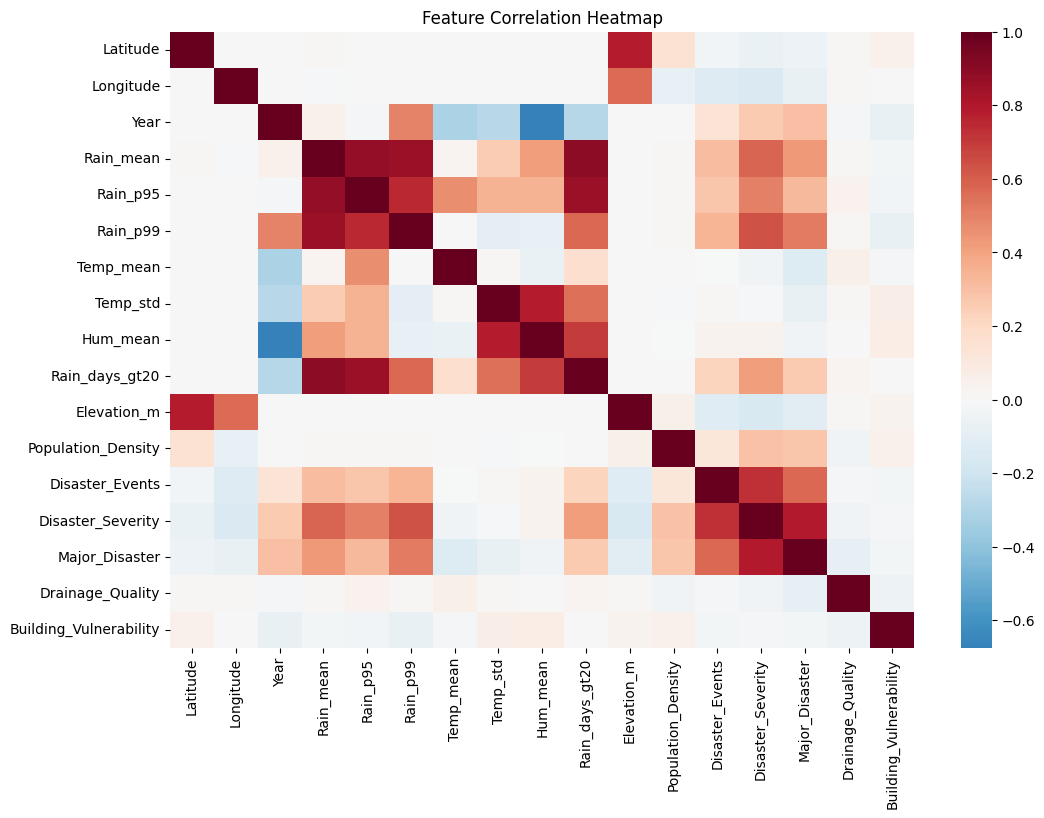

In [13]:
df_clipped = clip_outliers_iqr(df, numeric_cols=[c for c in numeric_cols if c not in ["Year"]])

# Correlation heatmap (numeric only)
corr = df_clipped.select_dtypes(include=[np.number]).corr()
plt.figure(figsize=(12, 8))
sns.heatmap(corr, cmap='RdBu_r', center=0)
plt.title('Feature Correlation Heatmap')
plt.show()

In [14]:
def compute_vif_matrix(X: pd.DataFrame) -> pd.DataFrame:
    """Compute Variance Inflation Factor for multicollinearity screening."""
    # VIF_i = 1 / (1 - R_i^2)
    from sklearn.linear_model import LinearRegression

    X_ = X.dropna().copy()
    vifs = []
    cols = list(X_.columns)
    for col in cols:
        y = X_[col].values
        X_other = X_.drop(columns=[col]).values
        if X_other.shape[1] == 0:
            vifs.append((col, 1.0))
            continue
        model = LinearRegression()
        model.fit(X_other, y)
        r2 = model.score(X_other, y)
        vif = 1.0 / max(1e-9, (1.0 - r2))
        vifs.append((col, vif))
    return pd.DataFrame(vifs, columns=["feature", "vif"]).sort_values("vif", ascending=False)

candidate_features = [
    'Rain_mean','Rain_p95','Rain_p99','Rain_days_gt20',
    'Temp_mean','Temp_std','Hum_mean',
    'Elevation_m','Population_Density','Drainage_Quality','Building_Vulnerability',
    'Disaster_Events','Disaster_Severity'
]

vif_df = compute_vif_matrix(df_clipped[candidate_features])
vif_df.head(20)

,feature,vif
0,Rain_mean,1.000000e+09
1,Rain_p95,1.000000e+09
2,Rain_p99,1.000000e+09
3,Rain_days_gt20,1.000000e+09
4,Temp_mean,1.000000e+09
5,Temp_std,1.000000e+09
6,Hum_mean,1.000000e+09
12,Disaster_Severity,4.401876e+00
11,Disaster_Events,2.458180e+00
8,Population_Density,1.253830e+00


In [15]:
def drop_high_vif_features(X: pd.DataFrame, threshold: float = 10.0) -> list[str]:
    """Iteratively remove features with high VIF."""
    remaining = list(X.columns)
    while True:
        vifs = compute_vif_matrix(X[remaining])
        worst = vifs.iloc[0]
        if worst['vif'] <= threshold or len(remaining) <= 2:
            break
        remaining.remove(worst['feature'])
    return remaining

selected_features = drop_high_vif_features(df_clipped[candidate_features], threshold=12.0)
print('Selected features after VIF filtering:', selected_features)

Selected features after VIF filtering: ['Rain_p99', 'Temp_mean', 'Temp_std', 'Hum_mean', 'Elevation_m', 'Population_Density', 'Drainage_Quality', 'Building_Vulnerability', 'Disaster_Events', 'Disaster_Severity']


## Create a learning target (risk score)

In [16]:
def minmax_01(x: np.ndarray) -> np.ndarray:
    x = np.asarray(x, dtype=float)
    return (x - np.nanmin(x)) / (np.nanmax(x) - np.nanmin(x) + 1e-9)

df2 = df_clipped.copy()

# Normalize components for synthetic target
sev_n = minmax_01(df2['Disaster_Severity'].values)
evt_n = minmax_01(df2['Disaster_Events'].values)
rain_n = minmax_01(df2['Rain_p99'].values)
rain_days_n = minmax_01(df2['Rain_days_gt20'].values)
pop_n = minmax_01(df2['Population_Density'].values)
vuln_n = minmax_01(df2['Building_Vulnerability'].values)
drain_n = 1.0 - minmax_01(df2['Drainage_Quality'].values)  # worse if low quality

true_risk = (
    0.30 * sev_n
    + 0.18 * evt_n
    + 0.18 * rain_n
    + 0.08 * rain_days_n
    + 0.14 * pop_n
    + 0.08 * vuln_n
    + 0.04 * drain_n
)

# Scale to 0..100 + noise
df2['RiskScore'] = np.clip(100 * true_risk + np.random.normal(0, 4.0, size=len(df2)), 0, 100)

def score_to_category(score: float) -> str:
    if score <= 30:
        return 'Low'
    if score <= 60:
        return 'Moderate'
    if score <= 80:
        return 'High'
    return 'Critical'

df2['RiskCategory'] = df2['RiskScore'].apply(score_to_category)
df2[['RiskScore','RiskCategory']].head()

,RiskScore,RiskCategory
0,22.335515,Low
1,29.459012,Low
2,50.946729,Moderate
3,29.112631,Low
4,11.468629,Low


In [17]:
# Train/test split
X = df2[selected_features].copy()
y_reg = df2['RiskScore'].copy()
y_clf = (df2['RiskCategory'].isin(['High','Critical'])).astype(int)  # binary example

X_train, X_test, y_train, y_test = train_test_split(
    X, y_reg,
    test_size=0.2,
    random_state=42,
)

X_train.shape, X_test.shape

((480, 10), (120, 10))

### Preprocessing pipeline

In [18]:
numeric_features = selected_features

preprocess = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])

# For convenience we keep a helper to transform into a numeric matrix
preprocess.fit(X_train)
X_train_t = preprocess.transform(X_train)
X_test_t = preprocess.transform(X_test)
X_train_t.shape

(480, 10)

# FEATURE ENGINEERING

In [ ]:
def add_engineered_features(frame: pd.DataFrame) -> pd.DataFrame:
    df = frame.copy()

    eps = 1e-9
    def norm01(series: pd.Series) -> pd.Series:
        return (series - series.min()) / (series.max() - series.min() + eps)

    evt_n = norm01(df['Disaster_Events'])
    sev_n = norm01(df['Disaster_Severity'])
    pop_n = norm01(df['Population_Density'])
    vuln_n = norm01(df['Building_Vulnerability'])
    drain_good_n = norm01(df['Drainage_Quality'])

    rain_p99_n = norm01(df['Rain_p99'])
    rain_days_n = norm01(df['Rain_days_gt20'])
    hum_n = norm01(df['Hum_mean'])

    df['HDFI'] = 0.6 * evt_n + 0.4 * sev_n
    df['Vulnerability_Score'] = 0.5 * vuln_n + 0.3 * (1 - drain_good_n) + 0.2 * pop_n
    df['Environmental_Stress_Index'] = 0.55 * rain_p99_n + 0.25 * rain_days_n + 0.20 * hum_n
    df['Composite_Risk_Index'] = (
        0.40 * df['HDFI']
        + 0.35 * df['Vulnerability_Score']
        + 0.25 * df['Environmental_Stress_Index']
    )

    return df

df3 = add_engineered_features(df2)
engineered_cols = ['HDFI','Vulnerability_Score','Environmental_Stress_Index','Composite_Risk_Index']

# Save engineered dataset for later reuse (evaluation without re-running feature engineering)
engineered_dataset_path = os.path.join(DATA_DIR, 'micro_zone_engineered_latest.csv')
df3.to_csv(engineered_dataset_path, index=False)
print('Saved engineered dataset:', engineered_dataset_path)

df3[engineered_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
HDFI,600.0,0.315110,0.205912,0.000000,0.137215,0.278743,0.441632,1.000000
Vulnerability_Score,600.0,0.426799,0.143706,0.077736,0.322674,0.421609,0.520762,0.956440
Environmental_Stress_Index,600.0,0.438418,0.258433,0.000000,0.192951,0.547214,0.596006,0.747122
Composite_Risk_Index,600.0,0.385028,0.136378,0.043364,0.287257,0.379674,0.483101,0.783083


In [22]:
# Visualize engineered feature distributions
fig = px.histogram(df3, x='Composite_Risk_Index', nbins=30, color='RiskCategory', title='Composite Risk Index Distribution')

# Plotly sometimes caches renderer availability at import time; ensure nbformat is picked up after installs.
import importlib
import plotly.io as pio

try:
    import nbformat  # noqa: F401
    import plotly.io._renderers as _renderers
    importlib.reload(_renderers)
    fig.show()
except Exception as e:
    print('Inline Plotly render failed; falling back to browser renderer. Error:', e)
    fig.show(renderer='browser')

Inline Plotly render failed; falling back to browser renderer. Error: Mime type rendering requires nbformat>=4.2.0 but it is not installed


In [23]:
final_features = selected_features + engineered_cols
X_full = df3[final_features].copy()
y_reg_full = df3['RiskScore'].copy()
y_clf_full = (df3['RiskCategory'].isin(['High','Critical'])).astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X_full, y_reg_full,
    test_size=0.2,
    random_state=42,
)

X_train.shape, X_test.shape

((480, 14), (120, 14))

# ML MODEL TRAINING

In [24]:
# Shared preprocessing for numeric features
numeric_features = final_features
preprocess = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])

rf = RandomForestRegressor(random_state=42, n_estimators=300)
xgb = XGBRegressor(
    random_state=42,
    n_estimators=500,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.9,
    colsample_bytree=0.9,
    reg_lambda=1.0,
    objective='reg:squarederror',
)

rf_pipe = Pipeline(steps=[('preprocess', preprocess), ('model', rf)])
xgb_pipe = Pipeline(steps=[('preprocess', preprocess), ('model', xgb)])

def eval_reg(model, X_tr, y_tr, X_te, y_te, name: str):
    model.fit(X_tr, y_tr)
    pred = model.predict(X_te)
    mae = mean_absolute_error(y_te, pred)
    rmse = math.sqrt(mean_squared_error(y_te, pred))
    r2 = r2_score(y_te, pred)
    return {"model": name, "MAE": mae, "RMSE": rmse, "R2": r2}

results = []
results.append(eval_reg(rf_pipe, X_train, y_train, X_test, y_test, 'RandomForestRegressor'))
results.append(eval_reg(xgb_pipe, X_train, y_train, X_test, y_test, 'XGBRegressor'))
pd.DataFrame(results).sort_values('RMSE')

,model,MAE,RMSE,R2
0,RandomForestRegressor,3.876745,4.839039,0.921438
1,XGBRegressor,3.856344,4.926432,0.918575


In [25]:
# GridSearchCV for XGB (keep it modest for demo)
param_grid = {
    'model__max_depth': [3, 5],
    'model__subsample': [0.8, 1.0],
    'model__colsample_bytree': [0.8, 1.0],
    'model__n_estimators': [300, 600],
}

grid = GridSearchCV(
    estimator=xgb_pipe,
    param_grid=param_grid,
    scoring='neg_root_mean_squared_error',
    cv=3,
    n_jobs=-1,
    verbose=1,
)
grid.fit(X_train, y_train)
print('Best params:', grid.best_params_)
best_xgb = grid.best_estimator_

best_pred = best_xgb.predict(X_test)
print('MAE:', mean_absolute_error(y_test, best_pred))
print('RMSE:', math.sqrt(mean_squared_error(y_test, best_pred)))
print('R2:', r2_score(y_test, best_pred))

Fitting 3 folds for each of 16 candidates, totalling 48 fits
Best params: {'model__colsample_bytree': 1.0, 'model__max_depth': 3, 'model__n_estimators': 300, 'model__subsample': 0.8}
MAE: 3.6786086680540566
RMSE: 4.713851928088911
R2: 0.9254506101694148


## Regression evaluation plots

In [ ]:
# ---- Regression evaluation plots (uses best_xgb, X_test, y_test) ----
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Ensure model + splits exist even if cells were run out of order
try:
    best_xgb
    X_test
    y_test
except NameError:
    # Minimal fallback: train a default XGB pipeline on the engineered feature set
    final_features = selected_features + engineered_cols
    X_full = df3[final_features].copy()
    y_reg_full = df3['RiskScore'].copy()

    X_train, X_test, y_train, y_test = train_test_split(
        X_full, y_reg_full, test_size=0.2, random_state=42
    )

    preprocess = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
    ])
    xgb = XGBRegressor(
        random_state=42, n_estimators=500, learning_rate=0.05, max_depth=5,
        subsample=0.9, colsample_bytree=0.9, reg_lambda=1.0, objective='reg:squarederror',
    )
    best_xgb = Pipeline(steps=[('preprocess', preprocess), ('model', xgb)])
    best_xgb.fit(X_train, y_train)

# Predict
best_pred = best_xgb.predict(X_test)

mae = mean_absolute_error(y_test, best_pred)
rmse = math.sqrt(mean_squared_error(y_test, best_pred))
r2 = r2_score(y_test, best_pred)
print({'MAE': mae, 'RMSE': rmse, 'R2': r2})

residuals = y_test.values - best_pred

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1) Predicted vs Actual
axes[0].scatter(y_test, best_pred, alpha=0.6)
min_v = float(np.min([y_test.min(), best_pred.min()]))
max_v = float(np.max([y_test.max(), best_pred.max()]))
axes[0].plot([min_v, max_v], [min_v, max_v], 'r--', linewidth=2)
axes[0].set_title('Predicted vs Actual (RiskScore)')
axes[0].set_xlabel('Actual')
axes[0].set_ylabel('Predicted')

# 2) Residuals vs Predicted
axes[1].scatter(best_pred, residuals, alpha=0.6)
axes[1].axhline(0, color='r', linestyle='--', linewidth=2)
axes[1].set_title('Residuals vs Predicted')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Residual (Actual - Predicted)')

# 3) Residual distribution
axes[2].hist(residuals, bins=30, edgecolor='k', alpha=0.8)
axes[2].set_title('Residual Distribution')
axes[2].set_xlabel('Residual')
axes[2].set_ylabel('Count')

plt.tight_layout()
plt.show()

In [26]:
# Classification model (Logistic Regression)
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_full, y_clf_full,
    test_size=0.2,
    random_state=42,
    stratify=y_clf_full,
)

clf_pipe = Pipeline(steps=[
    ('preprocess', Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
    ])),
    ('model', LogisticRegression(max_iter=2000, class_weight='balanced'))
])

clf_pipe.fit(X_train_c, y_train_c)
proba = clf_pipe.predict_proba(X_test_c)[:, 1]
pred = (proba >= 0.5).astype(int)
auc = roc_auc_score(y_test_c, proba)
print('ROC-AUC:', auc)
print(classification_report(y_test_c, pred))

ROC-AUC: 0.9960022844089093
              precision    recall  f1-score   support

           0       0.99      0.95      0.97       103
           1       0.76      0.94      0.84        17

    accuracy                           0.95       120
   macro avg       0.88      0.95      0.91       120
weighted avg       0.96      0.95      0.95       120



## Classification evaluation plots (ROC, PR, confusion matrix, calibration)

In [ ]:
# ---- Classification evaluation plots (uses clf_pipe, X_test_c, y_test_c) ----
from sklearn.metrics import (
    RocCurveDisplay, PrecisionRecallDisplay, ConfusionMatrixDisplay,
    roc_auc_score, average_precision_score, brier_score_loss,
 )

# Ensure we have probabilities even if the training cell wasn't run yet
try:
    proba
    X_test_c
    y_test_c
except NameError:
    # Refit quickly (same definitions as training cell)
    X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
        X_full, y_clf_full, test_size=0.2, random_state=42, stratify=y_clf_full
    )
    clf_pipe = Pipeline(steps=[
        ('preprocess', Pipeline(steps=[
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler()),
        ])),
        ('model', LogisticRegression(max_iter=2000, class_weight='balanced'))
    ])
    clf_pipe.fit(X_train_c, y_train_c)
    proba = clf_pipe.predict_proba(X_test_c)[:, 1]

pred = (proba >= 0.5).astype(int)

roc_auc = roc_auc_score(y_test_c, proba)
ap = average_precision_score(y_test_c, proba)
brier = brier_score_loss(y_test_c, proba)
print({'ROC_AUC': roc_auc, 'AvgPrecision': ap, 'Brier': brier})

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1) ROC
RocCurveDisplay.from_predictions(y_test_c, proba, ax=axes[0, 0], name=f'LogReg (AUC={roc_auc:.3f})')
axes[0, 0].plot([0, 1], [0, 1], 'k--', linewidth=1)
axes[0, 0].set_title('ROC Curve')

# 2) Precision-Recall
PrecisionRecallDisplay.from_predictions(y_test_c, proba, ax=axes[0, 1], name=f'LogReg (AP={ap:.3f})')
axes[0, 1].set_title('Precision–Recall Curve')

# 3) Confusion matrix @ 0.5 threshold
ConfusionMatrixDisplay.from_predictions(y_test_c, pred, ax=axes[1, 0], cmap='Blues', colorbar=False)
axes[1, 0].set_title('Confusion Matrix (threshold=0.50)')

# 4) Calibration curve (with fallback)
try:
    from sklearn.calibration import CalibrationDisplay
    CalibrationDisplay.from_predictions(
        y_test_c, proba, n_bins=10, strategy='quantile', ax=axes[1, 1], name='LogReg'
    )
    axes[1, 1].set_title('Calibration Curve (quantile bins)')
except Exception:
    from sklearn.calibration import calibration_curve
    prob_true, prob_pred = calibration_curve(y_test_c, proba, n_bins=10, strategy='quantile')
    axes[1, 1].plot(prob_pred, prob_true, marker='o')
    axes[1, 1].plot([0, 1], [0, 1], 'k--', linewidth=1)
    axes[1, 1].set_xlabel('Mean predicted probability')
    axes[1, 1].set_ylabel('Fraction of positives')
    axes[1, 1].set_title('Calibration Curve')

plt.tight_layout()
plt.show()

# Probability separation (safe matplotlib version)
plt.figure(figsize=(10, 4))
plt.hist(proba[y_test_c == 0], bins=30, density=True, alpha=0.55, label='Negative class')
plt.hist(proba[y_test_c == 1], bins=30, density=True, alpha=0.55, label='Positive class (High/Critical)')
plt.title('Predicted Probability Distributions')
plt.xlabel('Predicted probability of High/Critical')
plt.ylabel('Density')
plt.legend()
plt.tight_layout()
plt.show()

## Feature importance + SHAP

In [27]:
# Feature importances from best_xgb
xgb_model = best_xgb.named_steps['model']
importances = xgb_model.feature_importances_
imp_df = pd.DataFrame({"feature": final_features, "importance": importances}).sort_values('importance', ascending=False)
imp_df.head(15)

,feature,importance
13,Composite_Risk_Index,0.696402
9,Disaster_Severity,0.135359
0,Rain_p99,0.052795
5,Population_Density,0.029361
12,Environmental_Stress_Index,0.015139
10,HDFI,0.013682
1,Temp_mean,0.011867
2,Temp_std,0.007422
6,Drainage_Quality,0.007335
11,Vulnerability_Score,0.007009


In [32]:
import seaborn as sns
import matplotlib.pyplot as plt 
fig = px.bar(imp_df.head(20), x='importance', y='feature', orientation='h', title='Top Feature Importances (XGB)')
fig.update_layout(yaxis={'categoryorder':'total ascending'})
fig.show()

C:\Users\shiva\AppData\Local\Temp\ipykernel_33332\2303016757.py:16: FutureWarning:

The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.



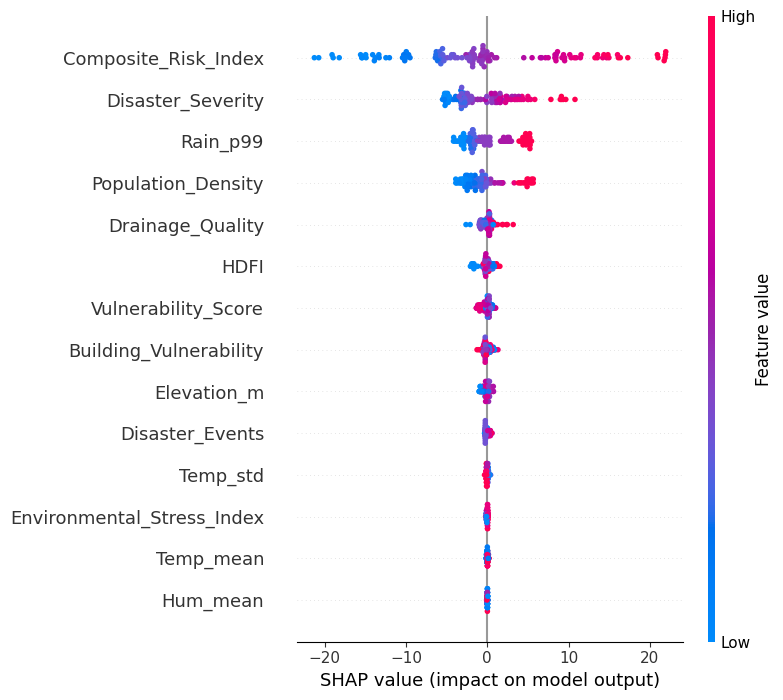

In [34]:
# SHAP explainability
# Important: SHAP expects a matrix in model feature space (after preprocessing).
import importlib
import matplotlib.pyplot as plt  # ensure matplotlib is importable before (re)loading shap

# If SHAP was imported before matplotlib got installed, it can cache a "no matplotlib" state.
importlib.reload(shap)

X_train_proc = best_xgb.named_steps['preprocess'].transform(X_train)
X_test_proc = best_xgb.named_steps['preprocess'].transform(X_test)

explainer = shap.TreeExplainer(best_xgb.named_steps['model'])
shap_values = explainer.shap_values(X_test_proc)

# Summary plot
shap.summary_plot(shap_values, X_test_proc, feature_names=final_features, show=True)

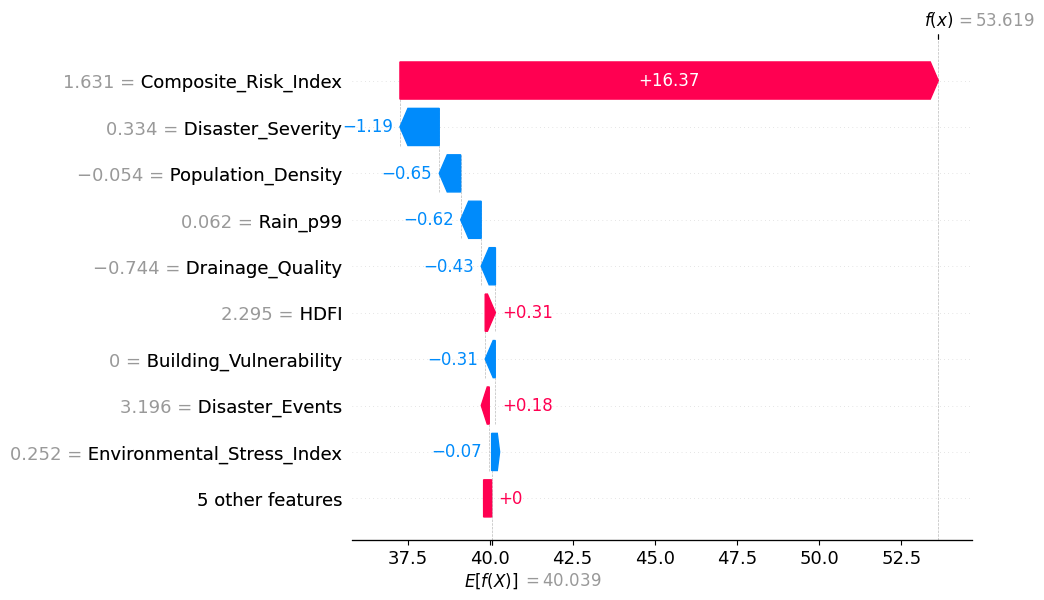

In [35]:
# Local explanation for one sample
sample_idx = 0
shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[sample_idx],
        base_values=explainer.expected_value,
        data=X_test_proc[sample_idx],
        feature_names=final_features,
    )
)

## Select best model and save artifact

In [36]:
def make_version_tag() -> str:
    return datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S')

version = make_version_tag()
trained_at = datetime.now(timezone.utc).isoformat().replace('+00:00', 'Z')

# SHAP background: small random sample from training after preprocessing
bg_idx = np.random.choice(np.arange(X_train.shape[0]), size=min(200, X_train.shape[0]), replace=False)
bg = best_xgb.named_steps['preprocess'].transform(X_train.iloc[bg_idx])

# Save a portable artifact (dict) so it can be loaded from notebooks, scripts, or FastAPI reliably
bundle = {
    'pipeline': best_xgb,
    'feature_names': final_features,
    'shap_background': bg,
    'trained_at_utc': trained_at,
    'version': version,
}

artifact_path = os.path.join(MODELS_DIR, f"risk_model_{version}.joblib")
joblib.dump(bundle, artifact_path)

# Also save a stable pointer for production usage
latest_path = os.path.join(MODELS_DIR, 'risk_model_latest.joblib')
joblib.dump(bundle, latest_path)

print('Saved:', artifact_path)
print('Saved latest pointer:', latest_path)

Saved: d:\AI-Based Micro-Zone Disaster Risk Scoring System\models\risk_model_20260218_155215.joblib
Saved latest pointer: d:\AI-Based Micro-Zone Disaster Risk Scoring System\models\risk_model_latest.joblib


## One-click evaluation from saved model artifact

In [ ]:
# ---- One-click evaluation (loads saved bundle + plots) ----
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    RocCurveDisplay, PrecisionRecallDisplay, ConfusionMatrixDisplay,
    roc_auc_score, average_precision_score, brier_score_loss,
 )

bundle_path = os.path.join(MODELS_DIR, 'risk_model_latest.joblib')
engineered_data_path = os.path.join(DATA_DIR, 'micro_zone_engineered_latest.csv')
fallback_data_path = os.path.join(DATA_DIR, 'disasterIND.csv')

if not os.path.exists(bundle_path):
    raise FileNotFoundError(f"Missing model bundle: {bundle_path}")

bundle = joblib.load(bundle_path)
if not isinstance(bundle, dict) or 'pipeline' not in bundle or 'feature_names' not in bundle:
    raise TypeError("Expected a dict bundle with keys: 'pipeline', 'feature_names'. Re-run training to regenerate.")

pipeline = bundle['pipeline']
feature_names = list(bundle['feature_names'])

# Prefer the in-notebook processed dataframe used during training; else load engineered dataset CSV; else fallback CSV
df_eval = None
source_name = None
try:
    df_eval = df3.copy()  # created in STEP 3 (feature engineering)
    source_name = 'df3 (in-notebook engineered dataset)'
except NameError:
    if os.path.exists(engineered_data_path):
        df_eval = pd.read_csv(engineered_data_path)
        source_name = f"CSV: {engineered_data_path}"
    elif os.path.exists(fallback_data_path):
        df_eval = pd.read_csv(fallback_data_path)
        source_name = f"CSV: {fallback_data_path}"
    else:
        raise FileNotFoundError(
            "No df3 in memory and no dataset found at either:\n"
            f"- {engineered_data_path}\n"
            f"- {fallback_data_path}"
        )

print('Evaluation source:', source_name)

# Rebuild engineered features if needed
try:
    add_engineered_features
except NameError:
    def add_engineered_features(frame: pd.DataFrame) -> pd.DataFrame:
        df = frame.copy()
        eps = 1e-9
        def norm01(series: pd.Series) -> pd.Series:
            return (series - series.min()) / (series.max() - series.min() + eps)

        required = [
            'Disaster_Events','Disaster_Severity','Population_Density','Building_Vulnerability','Drainage_Quality',
            'Rain_p99','Rain_days_gt20','Hum_mean',
        ]
        missing = [c for c in required if c not in df.columns]
        if missing:
            raise KeyError(f"Cannot compute engineered features; missing columns: {missing}")

        evt_n = norm01(df['Disaster_Events'])
        sev_n = norm01(df['Disaster_Severity'])
        pop_n = norm01(df['Population_Density'])
        vuln_n = norm01(df['Building_Vulnerability'])
        drain_good_n = norm01(df['Drainage_Quality'])

        rain_p99_n = norm01(df['Rain_p99'])
        rain_days_n = norm01(df['Rain_days_gt20'])
        hum_n = norm01(df['Hum_mean'])

        df['HDFI'] = 0.6 * evt_n + 0.4 * sev_n
        df['Vulnerability_Score'] = 0.5 * vuln_n + 0.3 * (1 - drain_good_n) + 0.2 * pop_n
        df['Environmental_Stress_Index'] = 0.55 * rain_p99_n + 0.25 * rain_days_n + 0.20 * hum_n
        df['Composite_Risk_Index'] = (
            0.40 * df['HDFI']
            + 0.35 * df['Vulnerability_Score']
            + 0.25 * df['Environmental_Stress_Index']
        )
        return df

df = df_eval.copy()
engineered_candidates = ['HDFI','Vulnerability_Score','Environmental_Stress_Index','Composite_Risk_Index']
if not all(c in df.columns for c in engineered_candidates):
    # Only attempt if the base columns exist; otherwise the evaluation dataset is incompatible
    try:
        df = add_engineered_features(df)
    except KeyError as e:
        raise KeyError(
            "Evaluation dataset does not match model feature schema. "
            "This model expects micro-zone engineered features (e.g., Rain_p99, Drainage_Quality). "
            "Use df3 (run STEP 1–3) or use the exported engineered dataset CSV at: "
            f"{engineered_data_path}. "
            f"Original error: {e}"
        )

# Align to model schema
missing_feats = [c for c in feature_names if c not in df.columns]
if missing_feats:
    raise KeyError(
        "Evaluation dataset is missing required model features: " + str(missing_feats) + "\n"
        "Tip: run STEP 1–3 to create df3 (and it will export a reusable engineered CSV)."
    )

X = df[feature_names].copy()

# Labels if available
y_reg = df['RiskScore'].astype(float) if 'RiskScore' in df.columns else None
y_bin = None
if 'RiskCategory' in df.columns:
    y_bin = df['RiskCategory'].isin(['High','Critical']).astype(int)

# Holdout split for evaluation
idx = np.arange(len(df))
if y_bin is not None and y_bin.nunique() > 1:
    idx_train, idx_test = train_test_split(idx, test_size=0.2, random_state=42, stratify=y_bin)
else:
    idx_train, idx_test = train_test_split(idx, test_size=0.2, random_state=42)

X_te = X.iloc[idx_test]
pred_score = pipeline.predict(X_te)
pred_score = np.clip(pred_score.astype(float), 0, 100)

# --- Regression plots (if RiskScore exists) ---
if y_reg is not None:
    y_te = y_reg.iloc[idx_test].values
    mae = mean_absolute_error(y_te, pred_score)
    rmse = math.sqrt(mean_squared_error(y_te, pred_score))
    r2 = r2_score(y_te, pred_score)
    print({'MAE': mae, 'RMSE': rmse, 'R2': r2})

    residuals = y_te - pred_score
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    axes[0].scatter(y_te, pred_score, alpha=0.6)
    min_v = float(np.min([np.min(y_te), np.min(pred_score)]))
    max_v = float(np.max([np.max(y_te), np.max(pred_score)]))
    axes[0].plot([min_v, max_v], [min_v, max_v], 'r--', linewidth=2)
    axes[0].set_title('Predicted vs Actual (RiskScore)')
    axes[0].set_xlabel('Actual')
    axes[0].set_ylabel('Predicted')

    axes[1].scatter(pred_score, residuals, alpha=0.6)
    axes[1].axhline(0, color='r', linestyle='--', linewidth=2)
    axes[1].set_title('Residuals vs Predicted')
    axes[1].set_xlabel('Predicted')
    axes[1].set_ylabel('Residual (Actual - Predicted)')

    axes[2].hist(residuals, bins=30, edgecolor='k', alpha=0.8)
    axes[2].set_title('Residual Distribution')
    axes[2].set_xlabel('Residual')
    axes[2].set_ylabel('Count')

    plt.tight_layout()
    plt.show()
else:
    print("Note: 'RiskScore' not found in evaluation dataset; skipping regression metrics/plots.")

# --- Classification plots (ROC/PR/etc) using predicted risk score as the ranking score ---
if y_bin is not None and y_bin.nunique() > 1:
    yb_te = y_bin.iloc[idx_test].values
    roc_auc = roc_auc_score(yb_te, pred_score)
    ap = average_precision_score(yb_te, pred_score)
    # Convert to a pseudo-probability for Brier by scaling score to [0,1]
    brier = brier_score_loss(yb_te, pred_score / 100.0)
    print({'ROC_AUC': roc_auc, 'AvgPrecision': ap, 'Brier(p~score/100)': brier})

    # Threshold at 60 corresponds to High/Critical boundary used elsewhere in notebook/API
    pred_bin = (pred_score >= 60.0).astype(int)

    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    RocCurveDisplay.from_predictions(yb_te, pred_score, ax=axes[0, 0], name=f'XGB score (AUC={roc_auc:.3f})')
    axes[0, 0].plot([0, 1], [0, 1], 'k--', linewidth=1)
    axes[0, 0].set_title('ROC Curve')

    PrecisionRecallDisplay.from_predictions(yb_te, pred_score, ax=axes[0, 1], name=f'XGB score (AP={ap:.3f})')
    axes[0, 1].set_title('Precision–Recall Curve')

    ConfusionMatrixDisplay.from_predictions(yb_te, pred_bin, ax=axes[1, 0], cmap='Blues', colorbar=False)
    axes[1, 0].set_title('Confusion Matrix (threshold=60)')

    try:
        from sklearn.calibration import CalibrationDisplay
        CalibrationDisplay.from_predictions(
            yb_te, pred_score / 100.0, n_bins=10, strategy='quantile', ax=axes[1, 1], name='XGB score/100'
        )
        axes[1, 1].set_title('Calibration Curve (score scaled to [0,1])')
    except Exception:
        from sklearn.calibration import calibration_curve
        prob_true, prob_pred = calibration_curve(yb_te, pred_score / 100.0, n_bins=10, strategy='quantile')
        axes[1, 1].plot(prob_pred, prob_true, marker='o')
        axes[1, 1].plot([0, 1], [0, 1], 'k--', linewidth=1)
        axes[1, 1].set_xlabel('Mean predicted probability')
        axes[1, 1].set_ylabel('Fraction of positives')
        axes[1, 1].set_title('Calibration Curve (score scaled)')

    plt.tight_layout()
    plt.show()
else:
    print("Note: 'RiskCategory' not found (or single class). Skipping ROC/PR/confusion/calibration plots.")

Evaluation source: CSV: d:\AI-Based Micro-Zone Disaster Risk Scoring System\data\disasterIND.csv


KeyError: 'Evaluation dataset does not match model feature schema. This model expects micro-zone engineered features (e.g., Rain_p99, Drainage_Quality). Use df3 (run STEP 1–3) or provide a processed dataset with the training feature columns. Original error: "Cannot compute engineered features; missing columns: [\'Disaster_Events\', \'Disaster_Severity\', \'Population_Density\', \'Building_Vulnerability\', \'Drainage_Quality\', \'Rain_p99\', \'Rain_days_gt20\', \'Hum_mean\']"'

In [37]:
# OPTIONAL (requires tensorflow or pytorch). This cell is informational and not required for the main pipeline.
# Example idea: sort by Zone_ID, Year and create sequences of last k years per zone.

SEQ_LEN = 3  # years
df_seq = df3.sort_values(['Zone_ID','Year']).copy()

def make_sequences(df_zone: pd.DataFrame, feature_cols: list[str], target_col: str, seq_len: int):
    Xs, ys = [], []
    values = df_zone[feature_cols].values
    targets = df_zone[target_col].values
    for i in range(seq_len, len(df_zone)):
        Xs.append(values[i-seq_len:i])
        ys.append(targets[i])
    return np.array(Xs), np.array(ys)

# Build sequences for a few zones as a demo
demo_zones = df_seq['Zone_ID'].unique()[:5]
X_list, y_list = [], []
for zid in demo_zones:
    d = df_seq[df_seq['Zone_ID'] == zid]
    Xs, ys = make_sequences(d, final_features, 'RiskScore', SEQ_LEN)
    if len(Xs) > 0:
        X_list.append(Xs)
        y_list.append(ys)

if len(X_list) > 0:
    X_lstm = np.concatenate(X_list, axis=0)
    y_lstm = np.concatenate(y_list, axis=0)
    print('Sequence tensor shape:', X_lstm.shape)
else:
    print('Not enough years per zone for sequences with SEQ_LEN=', SEQ_LEN)

Sequence tensor shape: (15, 3, 14)


# RISK SCORING ENGINE

In [38]:
def load_latest_bundle(models_dir: str = MODELS_DIR) -> dict:
    path = os.path.join(models_dir, 'risk_model_latest.joblib')
    if not os.path.exists(path):
        raise FileNotFoundError(f'No model artifact found at {path}. Train Step 4 first.')
    b = joblib.load(path)
    if not isinstance(b, dict):
        raise TypeError('Expected model artifact to be a dict bundle. Re-run Step 4 to regenerate artifacts.')
    return b

def map_score_to_category(score: float) -> str:
    if score <= 30:
        return 'Low'
    if score <= 60:
        return 'Moderate'
    if score <= 80:
        return 'High'
    return 'Critical'

def calculate_risk(zone_features: dict, zone_id: str | None = None, top_k: int = 5) -> dict:
    bundle = load_latest_bundle()

    pipeline = bundle['pipeline']
    feature_names = bundle['feature_names']
    shap_background = bundle['shap_background']

    # Build a single-row DataFrame aligned to feature schema
    row = {f: zone_features.get(f, np.nan) for f in feature_names}
    X_row = pd.DataFrame([row], columns=feature_names)

    # Predict
    score = float(pipeline.predict(X_row)[0])
    score = float(np.clip(score, 0, 100))
    category = map_score_to_category(score)

    # Explain with SHAP (in preprocessed space)
    X_proc = pipeline.named_steps['preprocess'].transform(X_row)
    explainer = shap.TreeExplainer(pipeline.named_steps['model'], data=shap_background)
    shap_vals = explainer.shap_values(X_proc)[0]

    contrib = pd.DataFrame({
        'feature': feature_names,
        'shap_value': shap_vals,
        'abs_shap': np.abs(shap_vals),
    }).sort_values('abs_shap', ascending=False)

    top = contrib.head(top_k)[['feature','shap_value']].to_dict(orient='records')

    return {
        'zone_id': zone_id,
        'risk_score': score,
        'risk_category': category,
        'top_contributing_features': top,
        'model_version': bundle.get('version'),
        'trained_at_utc': bundle.get('trained_at_utc'),
    }

# Demo: score one row from the dataset
example_row = X_full.iloc[0].to_dict()
example_zone_id = df3.iloc[0]['Zone_ID']
calculate_risk(example_row, zone_id=example_zone_id)

{'zone_id': 'Z0001',
 'risk_score': 23.29972267150879,
 'risk_category': 'Low',
 'top_contributing_features': [{'feature': 'Composite_Risk_Index',
   'shap_value': -4.661898035055492},
  {'feature': 'Population_Density', 'shap_value': -4.178565817889758},
  {'feature': 'Disaster_Severity', 'shap_value': -3.5960788857075388},
  {'feature': 'Rain_p99', 'shap_value': -1.533153174542822},
  {'feature': 'Elevation_m', 'shap_value': -1.3053508627484554}],
 'model_version': '20260218_155215',
 'trained_at_utc': '2026-02-18T15:52:15.876970Z'}

# API INTEGRATION


In [39]:
# Prepare latest-year zone features for dashboard listing
latest_year = int(df3['Year'].max())
zone_latest = df3[df3['Year'] == latest_year].copy()

# Score all zones (batch inference)
bundle = load_latest_bundle()
scores = bundle['pipeline'].predict(zone_latest[bundle['feature_names']])
zone_latest['PredictedRiskScore'] = np.clip(scores, 0, 100)
zone_latest['PredictedRiskCategory'] = zone_latest['PredictedRiskScore'].apply(map_score_to_category)

zone_latest[['Zone_ID','Year','PredictedRiskScore','PredictedRiskCategory']].head()

,Zone_ID,Year,PredictedRiskScore,PredictedRiskCategory
5,Z0001,2024,56.821003,Moderate
11,Z0002,2024,69.028969,High
17,Z0003,2024,61.664845,High
23,Z0004,2024,57.422901,Moderate
29,Z0005,2024,63.116371,High


In [40]:
# Build GeoDataFrame for mapping (polygons + scores)
zones_scored_gdf = zones_gdf.merge(
    zone_latest[['Zone_ID','PredictedRiskScore','PredictedRiskCategory']],
    on='Zone_ID',
    how='left'
)

# Category colors
cat_color = {
    'Low': '#2ca25f',
    'Moderate': '#fee08b',
    'High': '#fc8d59',
    'Critical': '#d73027',
}

center = [zones_scored_gdf['Latitude'].mean(), zones_scored_gdf['Longitude'].mean()]
m = folium.Map(location=center, zoom_start=12, tiles='cartodbpositron')

def style_fn(feature):
    cat = feature['properties'].get('PredictedRiskCategory')
    col = cat_color.get(cat, '#999999')
    return {
        'fillColor': col,
        'color': '#333333',
        'weight': 0.5,
        'fillOpacity': 0.55,
    }

tooltip = folium.GeoJsonTooltip(
    fields=['Zone_ID','PredictedRiskScore','PredictedRiskCategory'],
    aliases=['Zone','Risk Score','Category'],
    localize=True
)

geojson = folium.GeoJson(
    data=json.loads(zones_scored_gdf.to_json()),
    style_function=style_fn,
    tooltip=tooltip,
)
geojson.add_to(m)

m

In [41]:
# Plotly choropleth-like visualization using GeoJSON
geojson_data = json.loads(zones_scored_gdf.to_json())
fig = px.choropleth_mapbox(
    zones_scored_gdf,
    geojson=geojson_data,
    locations='Zone_ID',
    featureidkey='properties.Zone_ID',
    color='PredictedRiskScore',
    color_continuous_scale='RdYlGn_r',
    mapbox_style='carto-positron',
    center={'lat': center[0], 'lon': center[1]},
    zoom=11,
    opacity=0.6,
    hover_data=['PredictedRiskCategory'],
    title=f'Predicted Micro-Zone Risk (Year={latest_year})',
)
fig.update_layout(margin={'r':0,'t':40,'l':0,'b':0})
fig.show()

C:\Users\shiva\AppData\Local\Temp\ipykernel_33332\257481958.py:3: DeprecationWarning:

*choropleth_mapbox* is deprecated! Use *choropleth_map* instead. Learn more at: https://plotly.com/python/mapbox-to-maplibre/



In [42]:
# Generate FastAPI app example into api/app.py
fastapi_code = r'''
from __future__ import annotations

import os
from typing import Any

import numpy as np
import pandas as pd
import joblib
import shap

from fastapi import FastAPI, HTTPException
from pydantic import BaseModel


class ZoneFeatures(BaseModel):
    zone_id: str | None = None
    features: dict[str, float | int | None]


def map_score_to_category(score: float) -> str:
    if score <= 30:
        return 'Low'
    if score <= 60:
        return 'Moderate'
    if score <= 80:
        return 'High'
    return 'Critical'


def load_bundle(models_dir: str) -> dict:
    path = os.path.join(models_dir, 'risk_model_latest.joblib')
    if not os.path.exists(path):
        raise FileNotFoundError(f'Model not found at {path}')
    b = joblib.load(path)
    if not isinstance(b, dict):
        raise TypeError('Expected dict bundle artifact. Re-run training to regenerate artifacts.')
    return b


MODELS_DIR = os.path.abspath(os.path.join(os.path.dirname(__file__), '..', 'models'))
bundle = load_bundle(MODELS_DIR)

pipeline = bundle['pipeline']
feature_names = bundle['feature_names']
shap_background = bundle['shap_background']

app = FastAPI(title='Micro-Zone Disaster Risk Scoring API', version='1.0')


@app.get('/get_all_zones')
def get_all_zones():
    # Example endpoint: in production, query a database or feature store
    return {'message': 'Implement DB/feature-store lookup for zones here.'}


@app.post('/predict_zone_risk')
def predict_zone_risk(payload: ZoneFeatures):
    # Align to model schema
    row = {f: payload.features.get(f) for f in feature_names}
    X = pd.DataFrame([row], columns=feature_names)
    try:
        score = float(pipeline.predict(X)[0])
    except Exception as e:
        raise HTTPException(status_code=400, detail=f'Prediction error: {e}')

    score = float(np.clip(score, 0, 100))
    return {
        'zone_id': payload.zone_id,
        'risk_score': score,
        'risk_category': map_score_to_category(score),
        'model_version': bundle.get('version'),
        'trained_at_utc': bundle.get('trained_at_utc'),
    }


@app.post('/explain_zone')
def explain_zone(payload: ZoneFeatures):
    row = {f: payload.features.get(f) for f in feature_names}
    X = pd.DataFrame([row], columns=feature_names)

    try:
        X_proc = pipeline.named_steps['preprocess'].transform(X)
        explainer = shap.TreeExplainer(pipeline.named_steps['model'], data=shap_background)
        sv = explainer.shap_values(X_proc)[0]
        contrib = sorted(
            [{'feature': fn, 'shap_value': float(v), 'abs_shap': float(abs(v))} for fn, v in zip(feature_names, sv)],
            key=lambda d: d['abs_shap'],
            reverse=True,
        )
    except Exception as e:
        raise HTTPException(status_code=400, detail=f'Explain error: {e}')

    return {
        'zone_id': payload.zone_id,
        'top_contributing_features': contrib[:8],
        'model_version': bundle.get('version'),
    }


# Run: uvicorn api.app:app --reload
'''

api_path = os.path.join(API_DIR, 'app.py')
with open(api_path, 'w', encoding='utf-8') as f:
    f.write(fastapi_code)

print('Wrote FastAPI example to:', api_path)
print('Run with: uvicorn api.app:app --reload')

Wrote FastAPI example to: d:\AI-Based Micro-Zone Disaster Risk Scoring System\api\app.py
Run with: uvicorn api.app:app --reload


# REAL-TIME RECALIBRATION MODULE

In [43]:
def psi_for_feature(baseline: np.ndarray, new: np.ndarray, bins: int = 10) -> float:
    baseline = baseline.astype(float)
    new = new.astype(float)

    # Remove nan
    baseline = baseline[~np.isnan(baseline)]
    new = new[~np.isnan(new)]

    if len(baseline) < 10 or len(new) < 10:
        return 0.0

    # Define bins on baseline quantiles for stability
    quantiles = np.linspace(0, 1, bins + 1)
    edges = np.unique(np.quantile(baseline, quantiles))
    if len(edges) < 3:
        return 0.0

    # Histogram proportions
    p, _ = np.histogram(baseline, bins=edges)
    q, _ = np.histogram(new, bins=edges)

    p = p / max(1, p.sum())
    q = q / max(1, q.sum())

    # Avoid zeros
    eps = 1e-6
    p = np.clip(p, eps, 1.0)
    q = np.clip(q, eps, 1.0)

    return float(np.sum((q - p) * np.log(q / p)))

def check_drift(
    baseline_df: pd.DataFrame,
    new_df: pd.DataFrame,
    feature_cols: list[str],
    psi_threshold: float = 0.25,
    max_drifted_features: int = 3,
    ) -> dict:
    psi_scores = {}
    for col in feature_cols:
        psi_scores[col] = psi_for_feature(
            baseline_df[col].values,
            new_df[col].values,
            bins=10,
        )

    psi_series = pd.Series(psi_scores).sort_values(ascending=False)
    drifted = psi_series[psi_series >= psi_threshold]

    return {
        'psi_scores': psi_series.to_dict(),
        'drifted_features': drifted.to_dict(),
        'drift_detected': int(len(drifted) >= max_drifted_features),
        'psi_threshold': psi_threshold,
        'max_drifted_features': max_drifted_features,
    }

def retrain_model(
    train_df: pd.DataFrame,
    feature_cols: list[str],
    target_col: str = 'RiskScore',
    models_dir: str = MODELS_DIR,
    ) -> str:
    X = train_df[feature_cols].copy()
    y = train_df[target_col].copy()

    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)

    preprocess = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
    ])

    model = XGBRegressor(
        random_state=42,
        n_estimators=600,
        learning_rate=0.05,
        max_depth=5,
        subsample=0.9,
        colsample_bytree=0.9,
        reg_lambda=1.0,
        objective='reg:squarederror',
    )

    pipe = Pipeline(steps=[('preprocess', preprocess), ('model', model)])
    pipe.fit(X_tr, y_tr)

    pred = pipe.predict(X_te)
    rmse = math.sqrt(mean_squared_error(y_te, pred))
    r2 = r2_score(y_te, pred)
    print('Retrain RMSE:', rmse, 'R2:', r2)

    version = datetime.now(timezone.utc).strftime('%Y%m%d_%H%M%S')
    trained_at = datetime.now(timezone.utc).isoformat().replace('+00:00', 'Z')

    bg_idx = np.random.choice(np.arange(X_tr.shape[0]), size=min(200, X_tr.shape[0]), replace=False)
    bg = pipe.named_steps['preprocess'].transform(X_tr.iloc[bg_idx])

    bundle = {
        'pipeline': pipe,
        'feature_names': feature_cols,
        'shap_background': bg,
        'trained_at_utc': trained_at,
        'version': version,
    }

    artifact_path = os.path.join(models_dir, f"risk_model_{version}.joblib")
    joblib.dump(bundle, artifact_path)
    joblib.dump(bundle, os.path.join(models_dir, 'risk_model_latest.joblib'))
    return artifact_path

# Simulate new incoming data with drift by increasing extreme rainfall and density in some zones
new_data = df3[df3['Year'] == latest_year].copy()
new_data.loc[new_data.sample(frac=0.3, random_state=7).index, 'Rain_p99'] *= 1.35
new_data.loc[new_data.sample(frac=0.2, random_state=11).index, 'Population_Density'] *= 1.25
new_data = add_engineered_features(new_data)  # recompute engineered features after drift

baseline = df3[df3['Year'] == latest_year - 1].copy()
baseline = add_engineered_features(baseline)

drift_report = check_drift(baseline, new_data, feature_cols=final_features, psi_threshold=0.20, max_drifted_features=3)
print('Drift detected:', bool(drift_report['drift_detected']))
pd.Series(drift_report['drifted_features']).sort_values(ascending=False).head(10)

Drift detected: True


Disaster_Severity         10.306310
Composite_Risk_Index       1.788642
HDFI                       1.044700
Disaster_Events            0.437592
Building_Vulnerability     0.210835
Vulnerability_Score        0.204889
dtype: float64

In [44]:
# Auto-retrain if drift detected
if drift_report['drift_detected']:
    print('Drift trigger fired → retraining model...')
    # In a real system, train_df would include latest labeled outcomes (or delayed labels)
    # Here we use the full historical synthetic dataset as a stand-in.
    new_artifact = retrain_model(df3, feature_cols=final_features, target_col='RiskScore')
    print('Saved new model artifact:', new_artifact)
else:
    print('No retraining required.')

Drift trigger fired → retraining model...
Retrain RMSE: 4.937846291761326 R2: 0.9181973535114667
Saved new model artifact: d:\AI-Based Micro-Zone Disaster Risk Scoring System\models\risk_model_20260218_155446.joblib


In [45]:
# Smoke test (quick validation of artifacts + scoring)
latest_model_path = os.path.join(MODELS_DIR, 'risk_model_latest.joblib')
api_path = os.path.join(API_DIR, 'app.py')
print('Model artifact exists:', os.path.exists(latest_model_path), latest_model_path)
print('API app exists:', os.path.exists(api_path), api_path)

# If model exists, try one prediction
if os.path.exists(latest_model_path):
    b = load_latest_bundle()
    demo_row = X_full.iloc[0].to_dict()
    out = calculate_risk(demo_row, zone_id=str(df3.iloc[0]['Zone_ID']))
    print('calculate_risk output keys:', list(out.keys()))
    out
else:
    print('Train the model in Step 4 first, then re-run this cell.')

Model artifact exists: True d:\AI-Based Micro-Zone Disaster Risk Scoring System\models\risk_model_latest.joblib
API app exists: True d:\AI-Based Micro-Zone Disaster Risk Scoring System\api\app.py
calculate_risk output keys: ['zone_id', 'risk_score', 'risk_category', 'top_contributing_features', 'model_version', 'trained_at_utc']
